In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2

In [ ]:
# Sử dụng hàm convolve2d của Gấm
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

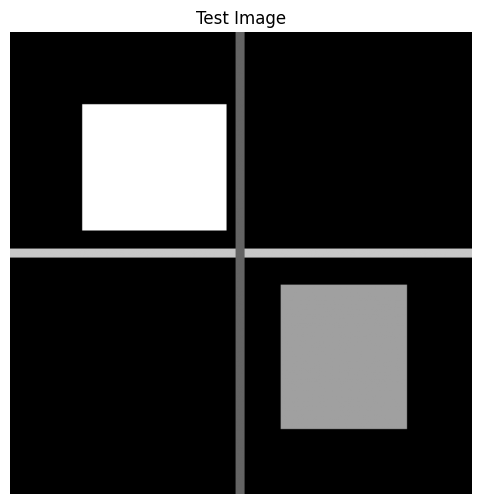

In [ ]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

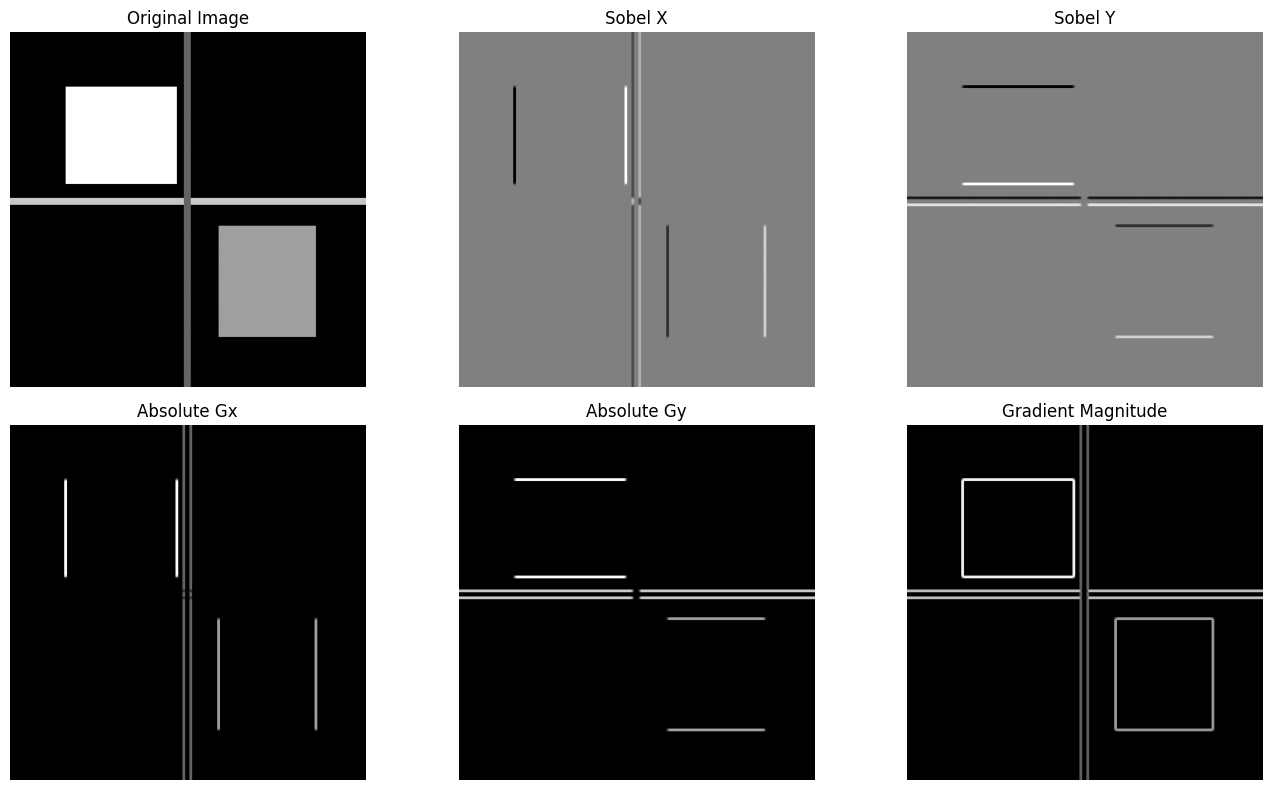

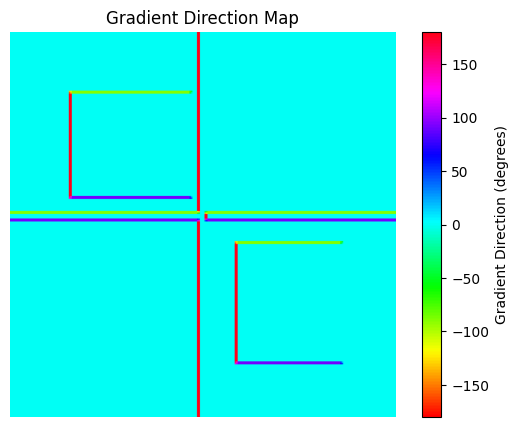

In [ ]:
#  Phát hiện cạnh bằng Sobel
img_float = img_demo.astype(np.float64)

# Define Sobel kernels
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# Apply the group's convolution function
gx = convolve2d(img_float, sobel_x, padding="reflect")
gy = convolve2d(img_float, sobel_y, padding="reflect")

# Calculate gradient magnitude and direction
edge_magnitude = np.sqrt(gx**2 + gy**2)
edge_direction = np.degrees(np.arctan2(gy, gx))

# Visualize the results
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(gx, cmap="gray")
axes[0, 1].set_title("Sobel X")

axes[0, 2].imshow(gy, cmap="gray")
axes[0, 2].set_title("Sobel Y")

axes[1, 0].imshow(np.abs(gx), cmap="gray")
axes[1, 0].set_title("Absolute Gx")

axes[1, 1].imshow(np.abs(gy), cmap="gray")
axes[1, 1].set_title("Absolute Gy")

axes[1, 2].imshow(edge_magnitude, cmap="gray")
axes[1, 2].set_title("Gradient Magnitude")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Display the gradient direction
plt.figure(figsize=(7, 5))
plt.imshow(
    edge_direction,
    cmap="hsv",
    vmin=-180,
    vmax=180
)
plt.colorbar(label="Gradient Direction (degrees)")
plt.title("Gradient Direction Map")
plt.axis("off")
plt.show()

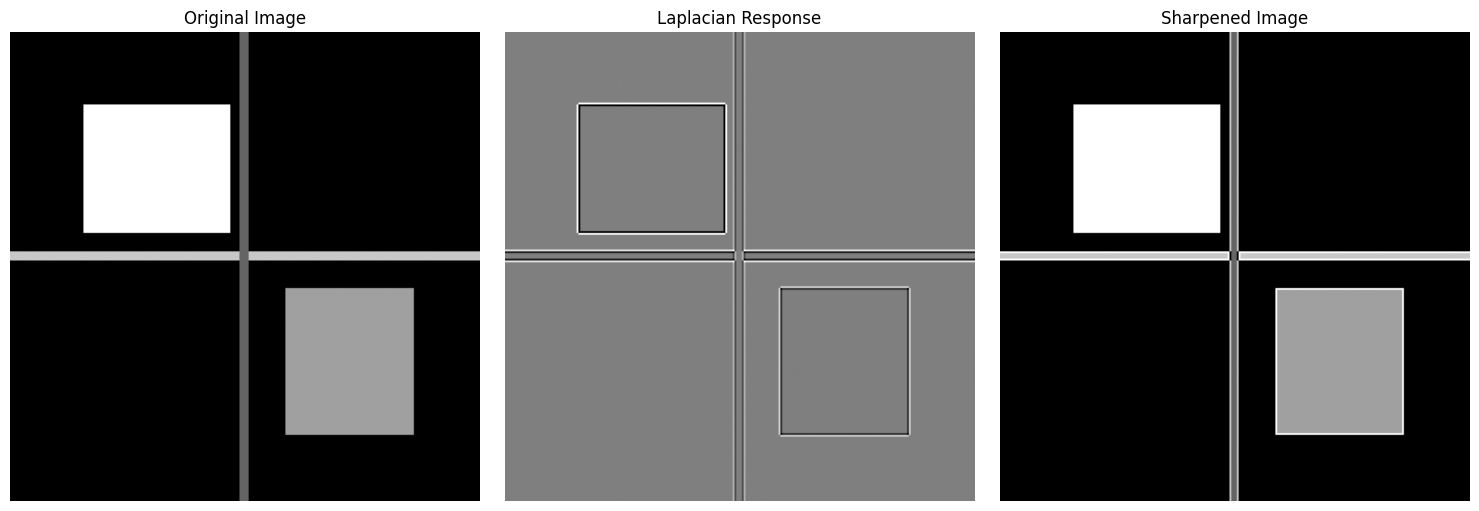

In [ ]:
# Làm sắc nét bằng Laplacian
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian convolution
laplacian = convolve2d(
    img_float,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the image
alpha = 1.0
sharpened_float = img_float - alpha * laplacian

# Clip pixel values to the valid range
sharpened = np.clip(
    np.round(sharpened_float),
    0,
    255
).astype(np.uint8)

# Normalize Laplacian for visualization only
laplacian_display = np.clip(
    127.5 + laplacian / 2,
    0,
    255
).astype(np.uint8)

# Compare the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    laplacian_display,
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title("Laplacian Response")

axes[2].imshow(
    sharpened,
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[2].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#  Kiểm tra kích thước và kết quả
print("Original image:", img_demo.shape, img_demo.dtype)
print("Sobel X:", gx.shape, gx.dtype)
print("Sobel Y:", gy.shape, gy.dtype)
print("Gradient magnitude:", edge_magnitude.shape)
print("Gradient direction:", edge_direction.shape)
print("Laplacian:", laplacian.shape)
print("Sharpened image:", sharpened.shape, sharpened.dtype)

print("\nMaximum gradient magnitude:",
      float(edge_magnitude.max()))

print("Number of pixels with nonzero gradient:",
      int(np.count_nonzero(edge_magnitude)))

print("All output shapes match:",
      img_demo.shape == gx.shape == gy.shape
      == edge_magnitude.shape == edge_direction.shape
      == laplacian.shape == sharpened.shape)

Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256)
Gradient direction: (256, 256)
Laplacian: (256, 256)
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
